
# 🌳 Decision Tree & Random Forest

# 1. Decision Tree

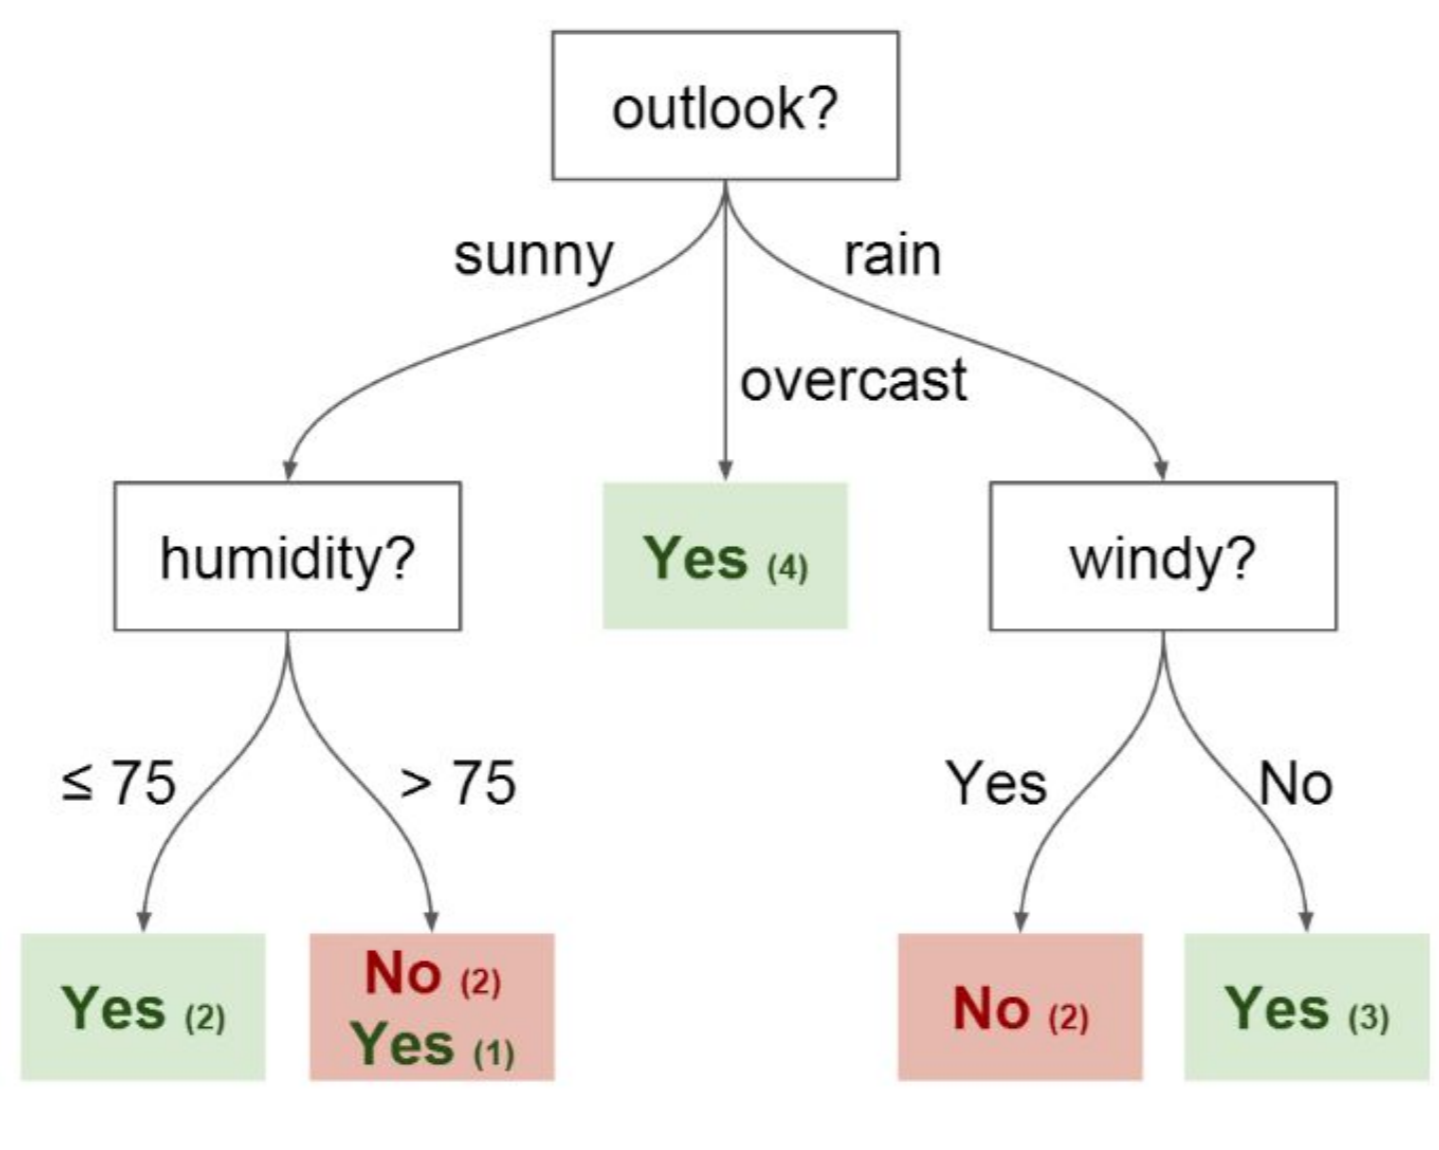

Decision Trees are an important type of algorithm for predictive modeling machine learning.

The classical decision tree algorithms have been around for decades and modern variations like random forest are among the most powerful techniques available.

Classification and Regression Trees or `CART` for short is a term introduced by `Leo Breiman` to refer to Decision Tree algorithms that can be used for classification or regression predictive modeling problems.

Classically, this algorithm is referred to as “`decision trees`”, but on some platforms like R they are referred to by the more modern term CART.

The `CART` algorithm provides a foundation for important algorithms like `bagged decision trees`, `random forest` and `boosted decision trees`.

### CART Model Representation
The representation for the CART model is a binary tree.

This is your binary tree from algorithms and data structures, nothing too fancy. Each root node represents a single input variable (x) and a split point on that variable (assuming the variable is numeric).

The leaf nodes of the tree contain an output variable (y) which is used to make a prediction.

Given a new input, the tree is traversed by evaluating the specific input started at the root node of the tree.

#### Some **advantages** of decision trees are:
* Simple to understand and to interpret. Trees can be visualised.
* Requires little data preparation. 
* Able to handle both numerical and categorical data.
* Possible to validate a model using statistical tests. 
* Performs well even if its assumptions are somewhat violated by the true model from which the data were generated.

#### The **disadvantages** of decision trees include:
* Overfitting. Mechanisms such as pruning (not currently supported), setting the minimum number of samples required at a leaf node or setting the maximum depth of the tree are necessary to avoid this problem.
* Decision trees can be unstable. Mitigant: Use decision trees within an ensemble.
* Cannot guarantee to return the globally optimal decision tree. Mitigant: Training multiple trees in an ensemble learner
* Decision tree learners create biased trees if some classes dominate. Recommendation: Balance the dataset prior to fitting

# 2. Random Forest
Random Forest is one of the most popular and most powerful machine learning algorithms. It is a type of ensemble machine learning algorithm called Bootstrap Aggregation or bagging.
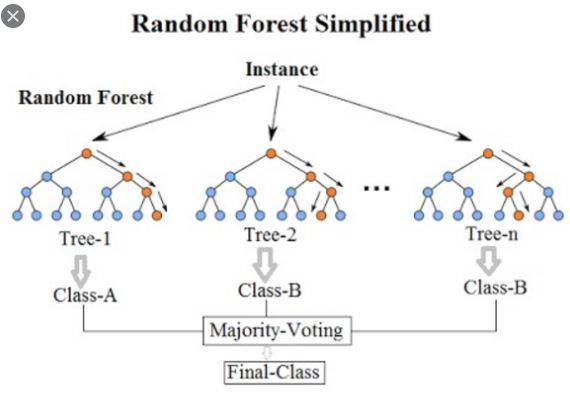
To improve performance of Decision trees, we can use many trees with a random sample of features chosen as the split.

# 3. Decision Tree & Random Forest Implementation in python

We will use Decision Tree & Random Forest in Predicting the attrition of your valuable employees.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_style("whitegrid")
plt.style.use("fivethirtyeight")

The dataset is found in [IBM HR Analytics Employee Attrition & Performance](https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset)

In [2]:
#df = pd.read_csv("/kaggle/input/ibm-hr-analytics-attrition-dataset/WA_Fn-UseC_-HR-Employee-Attrition.csv")
df = pd.read_csv("./data/week_3_WA_Fn-UseC_-HR-Employee-Attrition.csv")
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


# Exploratory Data Analysis

<Axes: xlabel='Attrition', ylabel='count'>

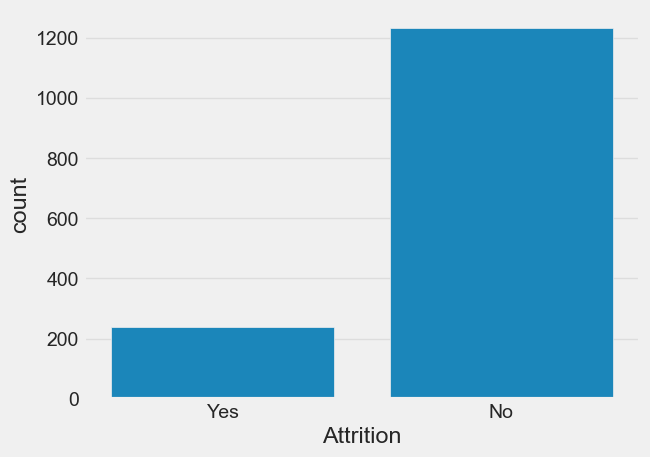

In [3]:
sns.countplot(x='Attrition', data=df)

In [4]:
df.drop(['EmployeeCount', 'EmployeeNumber', 'Over18', 'StandardHours'], axis="columns", inplace=True)

categorical_col = []
for column in df.columns:
    if df[column].dtype == object and len(df[column].unique()) <= 50:
        categorical_col.append(column)
        
df['Attrition'] = df.Attrition.astype("category").cat.codes

# Data Processing

In [5]:
categorical_col.remove('Attrition')

In [6]:
# Transform categorical data into dummies
# categorical_col.remove("Attrition")
# data = pd.get_dummies(df, columns=categorical_col)
# data.info()
from sklearn.preprocessing import LabelEncoder

label = LabelEncoder()
for column in categorical_col:
    df[column] = label.fit_transform(df[column])

In [7]:
from sklearn.model_selection import train_test_split

X = df.drop('Attrition', axis=1)
y = df.Attrition

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Applying Tree & Random Forest algorithms

In [8]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
from IPython.display import display, Markdown


def print_score(clf, X_train, y_train, X_test, y_test, train=True):
    if train:
        pred = clf.predict(X_train)
        clf_report = pd.DataFrame(classification_report(y_train, pred, output_dict=True))
        print("Train Result:\n================================================")
        print(f"Accuracy Score: {accuracy_score(y_train, pred) * 100:.2f}%")
        print("_______________________________________________")
        print(f"CLASSIFICATION REPORT:\n{clf_report}")
        print("_______________________________________________")
        print(f"Confusion Matrix: \n {confusion_matrix(y_train, pred)}\n")
        
    elif train==False:
        pred = clf.predict(X_test)
        clf_report = pd.DataFrame(classification_report(y_test, pred, output_dict=True))
        print("Test Result:\n================================================")        
        print(f"Accuracy Score: {accuracy_score(y_test, pred) * 100:.2f}%")
        print("_______________________________________________")
        print(f"CLASSIFICATION REPORT:\n{clf_report}")
        print("_______________________________________________")
        print(f"Confusion Matrix: \n {confusion_matrix(y_test, pred)}\n")

def print_score(clf, X_train, y_train, X_test, y_test, train=True):
    X, y = (X_train, y_train) if train else (X_test, y_test)
    split = "Train" if train else "Test"
    pred = clf.predict(X)

    display(Markdown(f"## {split} Results"))
    display(Markdown(f"**Accuracy:** {accuracy_score(y, pred):.2%}"))

    # Accuracy is shown separately, so omit it from the report table.
    report = classification_report(
        y, pred, output_dict=True, zero_division=0
    )
    report.pop("accuracy", None)
    report_df = pd.DataFrame(report).T.rename_axis("Class / Average")

    display(Markdown("### Classification Report"))
    display(
        report_df.style
        .format({
            "precision": "{:.3f}",
            "recall": "{:.3f}",
            "f1-score": "{:.3f}",
            "support": "{:,.0f}",
        })
        .background_gradient(
            cmap="Blues",
            subset=["precision", "recall", "f1-score"],
            vmin=0,
            vmax=1,
        )
    )

    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay.from_predictions(
        y,
        pred,
        cmap="Blues",
        values_format="d",
        colorbar=False,
        ax=ax,
    )
    ax.set_title(f"{split} Confusion Matrix")
    fig.tight_layout()
    plt.show()

## 1. Decision Tree Classifier

**Decision Tree parameters:**
- `criterion`: The function to measure the quality of a split. Supported criteria are "`gini`" for the Gini impurity and "`entropy`" for the information gain.
***
- `splitter`: The strategy used to choose the split at each node. Supported strategies are "`best`" to choose the best split and "`random`" to choose the best random split.
***
- `max_depth`: The maximum depth of the tree. If None, then nodes are expanded until all leaves are pure or until all leaves contain less than `min_samples_split` samples.
***
- `min_samples_split`: The minimum number of samples required to split an internal node.
***
- `min_samples_leaf`: The minimum number of samples required to be at a leaf node. A split point at any depth will only be considered if it leaves at least ``min_samples_leaf`` training samples in each of the left and right branches.  This may have the effect of smoothing the model, especially in regression.
***
- `min_weight_fraction_leaf`: The minimum weighted fraction of the sum total of weights (of all the input samples) required to be at a leaf node. Samples have equal weight when sample_weight is not provided.
***
- `max_features`: The number of features to consider when looking for the best split.
***
- `max_leaf_nodes`: Grow a tree with ``max_leaf_nodes`` in best-first fashion. Best nodes are defined as relative reduction in impurity. If None then unlimited number of leaf nodes.
***
- `min_impurity_decrease`: A node will be split if this split induces a decrease of the impurity greater than or equal to this value.
***
- `min_impurity_split`: Threshold for early stopping in tree growth. A node will split if its impurity is above the threshold, otherwise it is a leaf.

## Train Results

**Accuracy:** 100.00%

### Classification Report

,precision,recall,f1-score,support
Class / Average,,,,
0,1.000,1.000,1.000,853
1,1.000,1.000,1.000,176
macro avg,1.000,1.000,1.000,"1,029"
weighted avg,1.000,1.000,1.000,"1,029"


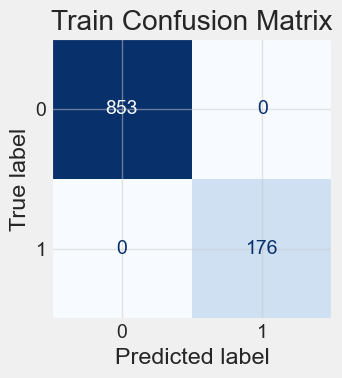

## Test Results

**Accuracy:** 77.78%

### Classification Report

,precision,recall,f1-score,support
Class / Average,,,,
0,0.887,0.850,0.868,380
1,0.260,0.328,0.290,61
macro avg,0.574,0.589,0.579,441
weighted avg,0.801,0.778,0.788,441


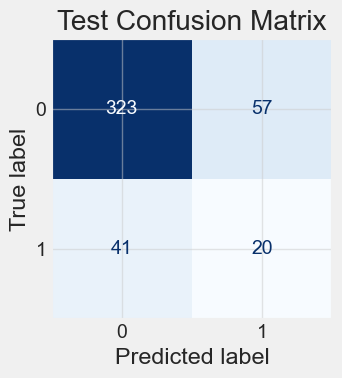

In [9]:
from sklearn.tree import DecisionTreeClassifier

tree_clf = DecisionTreeClassifier(random_state=42)
tree_clf.fit(X_train, y_train)

print_score(tree_clf, X_train, y_train, X_test, y_test, train=True)
print_score(tree_clf, X_train, y_train, X_test, y_test, train=False)

## 2. Decision Tree Classifier Hyperparameter tuning

### Dataset source and GridSearchCV warning

This notebook uses the **IBM HR Analytics Employee Attrition & Performance** dataset, available on [Kaggle](https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset). The original CSV is `WA_Fn-UseC_-HR-Employee-Attrition.csv`; this project loads its local copy from `./data/week_3_WA_Fn-UseC_-HR-Employee-Attrition.csv`. The target column is `Attrition`.

#### Why the warning occurs

Some older scikit-learn versions can emit `RuntimeWarning: invalid value encountered in cast` during `GridSearchCV.fit()`. In the traceback observed here, the warning occurs while formatting the search results, in `_yield_masked_array_for_each_param`, rather than while displaying the classification report.

The affected code creates an uninitialized floating-point array with `np.empty(n_candidates)` and then casts it to the parameter's data type when constructing a NumPy masked array. When that type is an integer, the temporary memory contents can contain values that cannot be converted cleanly. This makes the warning intermittent. This specific traceback does not establish that the dataset contains missing or invalid values.

See the [scikit-learn bug report #29929](https://github.com/scikit-learn/scikit-learn/issues/29929) and [upstream fix #29977](https://github.com/scikit-learn/scikit-learn/pull/29977), merged on 7 October 2024. The fix allocates the array with the intended data type from the outset.

#### Resolution

Upgrade scikit-learn to a version containing the fix, then restart the notebook kernel. In a notebook, `%pip install --upgrade scikit-learn` upgrades the package in the kernel's environment.

If the existing environment must be retained, narrowly suppress the known warning around the search call:

```python
import warnings

with warnings.catch_warnings():
    warnings.filterwarnings(
        "ignore",
        message="invalid value encountered in cast",
        category=RuntimeWarning,
        module=r"numpy\.ma\.core",
    )
    tree_cv.fit(X_train, y_train)
```

This is a workaround, not a library fix. Remove temporary debugging filters that turn warnings into errors when they are no longer needed.

In [10]:
import warnings

catch_or_raise_the_warning = "ignore" # By default, leave it as ignore

if catch_or_raise_the_warning == "catch":
    # Catch the warning

    warnings.filterwarnings(
        "error",
        message="invalid value encountered in cast",
        category=RuntimeWarning,
    )
else:
    # Filter the warning
    warnings.filterwarnings(
        "ignore",
        message="invalid value encountered in cast",
        category=RuntimeWarning,
        module=r"numpy\.ma\.core",
    )


Fitting 5 folds for each of 4332 candidates, totalling 21660 fits
Best parameters: {'criterion': 'entropy', 'max_depth': 4, 'min_samples_leaf': 19, 'min_samples_split': 2, 'splitter': 'best'})


## Train Results

**Accuracy:** 86.69%

### Classification Report

,precision,recall,f1-score,support
Class / Average,,,,
0,0.879,0.973,0.924,853
1,0.729,0.352,0.475,176
macro avg,0.804,0.663,0.699,"1,029"
weighted avg,0.854,0.867,0.847,"1,029"


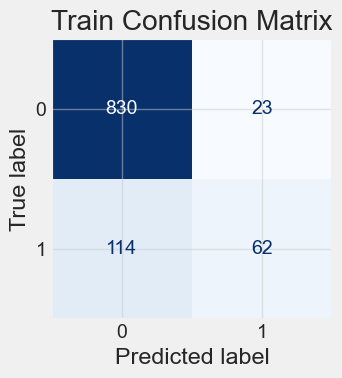

## Test Results

**Accuracy:** 86.85%

### Classification Report

,precision,recall,f1-score,support
Class / Average,,,,
0,0.885,0.974,0.927,380
1,0.565,0.213,0.310,61
macro avg,0.725,0.593,0.618,441
weighted avg,0.841,0.868,0.842,441


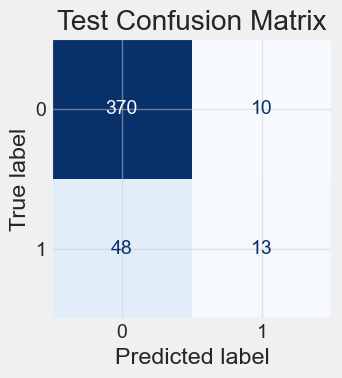

In [11]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

params = {
    "criterion":("gini", "entropy"), 
    "splitter":("best", "random"), 
    "max_depth":(list(range(1, 20))), 
    "min_samples_split":[2, 3, 4], 
    "min_samples_leaf":list(range(1, 20)), 
}


tree_clf = DecisionTreeClassifier(random_state=42)
tree_cv = GridSearchCV(
    tree_clf, 
    params, 
    scoring="f1", 
    n_jobs=-1, 
    verbose=1, 
    cv=5
)

tree_cv.fit(X_train, y_train)
best_params = tree_cv.best_params_
print(f"Best parameters: {best_params})")

tree_clf = DecisionTreeClassifier(**best_params)
tree_clf.fit(X_train, y_train)
print_score(tree_clf, X_train, y_train, X_test, y_test, train=True)
print_score(tree_clf, X_train, y_train, X_test, y_test, train=False)

### Visualization of a tree

In [12]:
from IPython.display import Image
from six import StringIO
from sklearn.tree import export_graphviz
import pydot

features = list(df.columns)
features.remove("Attrition")

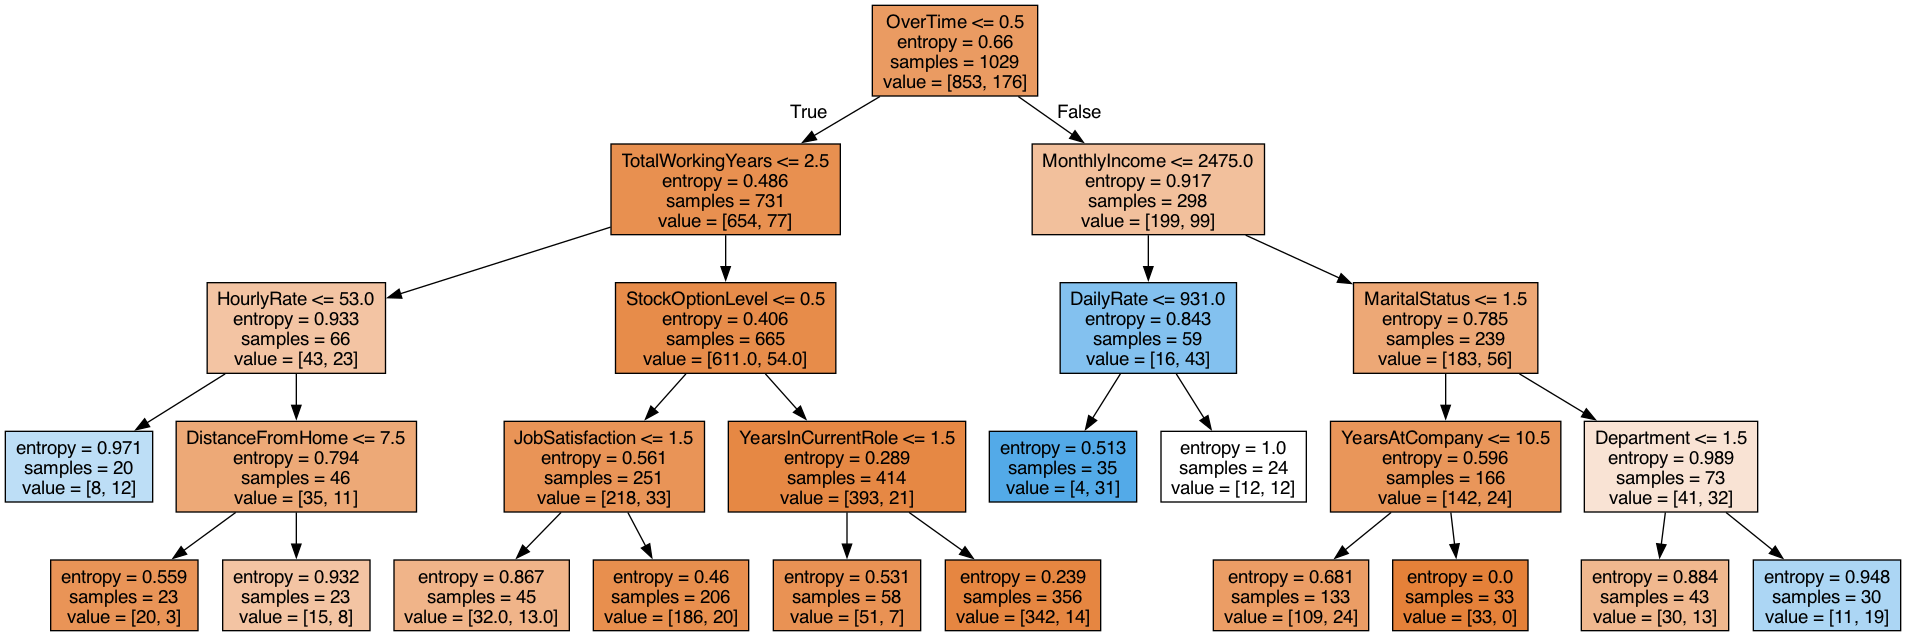

In [13]:
dot_data = StringIO()
export_graphviz(tree_clf, out_file=dot_data, feature_names=features, filled=True)
graph = pydot.graph_from_dot_data(dot_data.getvalue())
Image(graph[0].create_png())

# 3. Random Forest

A random forest is a meta estimator that fits a number of decision tree classifiers on various sub-samples of the dataset and uses averaging to improve the predictive accuracy and control over-fitting.

- **Random forest algorithm parameters:**
- `n_estimators`: The number of trees in the forest.
*** 
- `criterion`: The function to measure the quality of a split. Supported criteria are "`gini`" for the Gini impurity and "`entropy`" for the information gain.
***
- `max_depth`: The maximum depth of the tree. If None, then nodes are expanded until all leaves are pure or until all leaves contain less than `min_samples_split` samples.
***
- `min_samples_split`: The minimum number of samples required to split an internal node.
***
- `min_samples_leaf`: The minimum number of samples required to be at a leaf node. A split point at any depth will only be considered if it leaves at least ``min_samples_leaf`` training samples in each of the left and right branches.  This may have the effect of smoothing the model, especially in regression.
***
- `min_weight_fraction_leaf`: The minimum weighted fraction of the sum total of weights (of all the input samples) required to be at a leaf node. Samples have equal weight when sample_weight is not provided.
***
- `max_features`: The number of features to consider when looking for the best split.
***
- `max_leaf_nodes`: Grow a tree with ``max_leaf_nodes`` in best-first fashion. Best nodes are defined as relative reduction in impurity. If None then unlimited number of leaf nodes.
***
- `min_impurity_decrease`: A node will be split if this split induces a decrease of the impurity greater than or equal to this value.
***
- `min_impurity_split`: Threshold for early stopping in tree growth. A node will split if its impurity is above the threshold, otherwise it is a leaf.
***
- `bootstrap`: Whether bootstrap samples are used when building trees. If False, the whole datset is used to build each tree.
***
- `oob_score`: Whether to use out-of-bag samples to estimate the generalization accuracy.

## Train Results

**Accuracy:** 100.00%

### Classification Report

,precision,recall,f1-score,support
Class / Average,,,,
0,1.000,1.000,1.000,853
1,1.000,1.000,1.000,176
macro avg,1.000,1.000,1.000,"1,029"
weighted avg,1.000,1.000,1.000,"1,029"


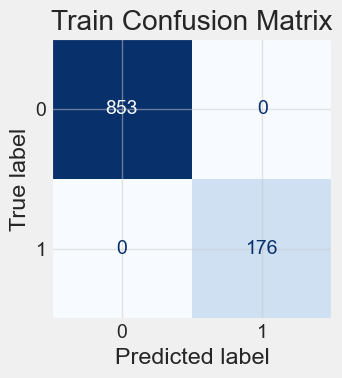

## Test Results

**Accuracy:** 85.94%

### Classification Report

,precision,recall,f1-score,support
Class / Average,,,,
0,0.870,0.984,0.923,380
1,0.455,0.082,0.139,61
macro avg,0.662,0.533,0.531,441
weighted avg,0.812,0.859,0.815,441


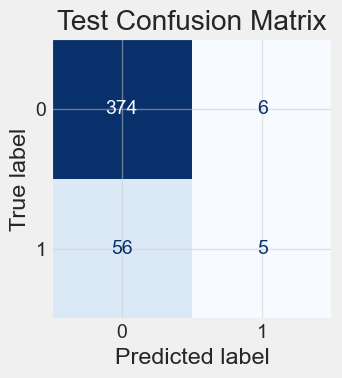

In [14]:
from sklearn.ensemble import RandomForestClassifier

rf_clf = RandomForestClassifier(n_estimators=100)
rf_clf.fit(X_train, y_train)

print_score(rf_clf, X_train, y_train, X_test, y_test, train=True)
print_score(rf_clf, X_train, y_train, X_test, y_test, train=False)

## 4. Random Forest hyperparameter tuning

### a) Randomized Search Cross Validation

Reference [RandomizedSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html)

`class sklearn.model_selection.RandomizedSearchCV(estimator, param_distributions, *, n_iter=10, scoring=None, n_jobs=None, refit=True, cv=None, verbose=0, pre_dispatch='2*n_jobs', random_state=None, error_score=nan, return_train_score=False)`

### Replacing the obsolete `max_features="auto"`

Older examples use `max_features="auto"` for `RandomForestClassifier`. This option was deprecated and is no longer accepted by current versions. Candidates containing it fail during cross-validation and receive `NaN` scores. Update the parameter lists in both randomized and grid searches rather than suppressing the resulting warnings.

For this classifier, the old `"auto"` behavior is equivalent to `"sqrt"`. `max_features` controls the number of randomly selected features considered at each split.

| Alternative | Meaning |
| --- | --- |
| `"sqrt"` | Square root of the feature count, rounded down with a minimum of one. Preserves the old classifier behavior. |
| `"log2"` | Base-2 logarithm of the feature count, rounded down with a minimum of one. |
| `None` | Consider all features. |
| Integer, e.g. `5` | Specify a feature count directly. |
| Float, e.g. `0.5` | Specify a fraction of the features, rounded down with a minimum of one. |

For example, with 30 input features, `"sqrt"` selects 5 features per split and `"log2"` selects 4. The splitter may inspect additional features if necessary to find a valid partition.

Use one of these search configurations:

```python
# Preserve the old "auto" behavior; tune the other parameters only.
max_features = ["sqrt"]

# Alternatively, let cross-validation compare two strategies.
max_features = ["sqrt", "log2"]
```

Use the chosen list as the value of `"max_features"` in the search dictionary. A two-option list expands the choices available to the search; it does not apply both strategies at once to a single model. With a fixed `n_iter`, randomized search still samples that many candidates (subject to the available combinations).

The `"auto"` → `"sqrt"` equivalence here applies specifically to **RandomForestClassifier**.

Source: [scikit-learn RandomForestClassifier documentation](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html).

In [17]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV

n_estimators = [int(x) for x in np.linspace(start=200, stop=2000, num=10)]
max_features =  ["sqrt", "log2"] # Deprecated: max_features = ['auto', 'sqrt']
#max_features =  ["sqrt"] # Deprecated: max_features = ['auto', 'sqrt']
max_depth = [int(x) for x in np.linspace(10, 110, num=11)]
max_depth.append(None)
min_samples_split = [2, 5, 10]
min_samples_leaf = [1, 2, 4]
bootstrap = [True, False]

random_grid = {
    'n_estimators': n_estimators,
    'max_features': max_features,
    'max_depth': max_depth,
    'min_samples_split': min_samples_split,
    'min_samples_leaf': min_samples_leaf,
    'bootstrap': bootstrap
}

rf_clf = RandomForestClassifier(random_state=42)

rf_cv = RandomizedSearchCV(
    estimator=rf_clf,
    scoring='f1',
    param_distributions=random_grid,
    n_iter=200,
    cv=5,
    verbose=1,
    random_state=42,
    n_jobs=-1, # -1 means using all processors.
    error_score="raise", # stop immediately on future fitting errors
)

rf_cv.fit(X_train, y_train)
rf_best_params = rf_cv.best_params_
print(f"Best paramters: {rf_best_params})")

rf_clf = RandomForestClassifier(**rf_best_params)
rf_clf.fit(X_train, y_train)

print_score(rf_clf, X_train, y_train, X_test, y_test, train=True)
print_score(rf_clf, X_train, y_train, X_test, y_test, train=False)

Fitting 5 folds for each of 200 candidates, totalling 1000 fits


InvalidParameterError: The 'max_features' parameter of RandomForestClassifier must be an int in the range [1, inf), a float in the range (0.0, 1.0], a str among {'log2', 'sqrt'} or None. Got 'auto' instead.

`Random search` allowed us to narrow down the range for each hyperparameter. Now that we know where to concentrate our search, we can explicitly specify every combination of settings to try. We do this with `GridSearchCV`, a method that, instead of sampling randomly from a distribution, evaluates all combinations we define.

### b) Grid Search Cross Validation

Reference: [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)

`class sklearn.model_selection.GridSearchCV(estimator, param_grid, *, scoring=None, n_jobs=None, refit=True, cv=None, verbose=0, pre_dispatch='2*n_jobs', error_score=nan, return_train_score=False)`

Fitting 5 folds for each of 768 candidates, totalling 3840 fits
Best parameters: {'bootstrap': False, 'max_depth': None, 'max_features': 'log2', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100}


## Train Results

**Accuracy:** 100.00%

### Classification Report

,precision,recall,f1-score,support
Class / Average,,,,
0,1.000,1.000,1.000,853
1,1.000,1.000,1.000,176
macro avg,1.000,1.000,1.000,"1,029"
weighted avg,1.000,1.000,1.000,"1,029"


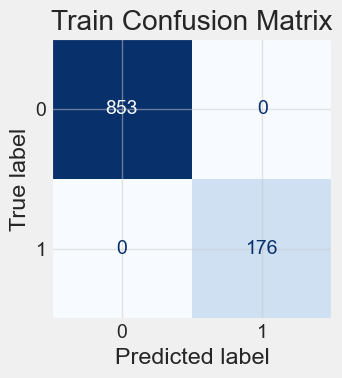

## Test Results

**Accuracy:** 86.39%

### Classification Report

,precision,recall,f1-score,support
Class / Average,,,,
0,0.874,0.984,0.926,380
1,0.538,0.115,0.189,61
macro avg,0.706,0.549,0.557,441
weighted avg,0.827,0.864,0.824,441


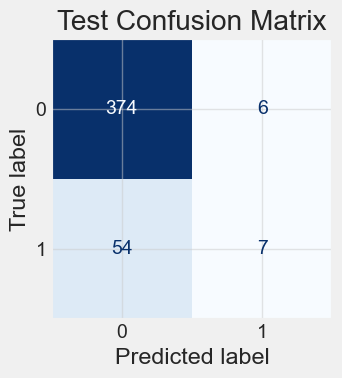

In [18]:
n_estimators = [100, 500, 1000, 1500]
max_features =  ["sqrt", "log2"] # Deprecated: max_features = ['auto', 'sqrt']
#max_features =  ["sqrt"] # Deprecated: max_features = ['auto', 'sqrt']
max_depth = [2, 3, 5]
max_depth.append(None)
min_samples_split = [2, 5, 10]
min_samples_leaf = [1, 2, 4, 10]
bootstrap = [True, False]

params_grid = {
    'n_estimators': n_estimators, 
    'max_features': max_features,
    'max_depth': max_depth, 
    'min_samples_split': min_samples_split,
    'min_samples_leaf': min_samples_leaf, 
    'bootstrap': bootstrap
}

rf_clf = RandomForestClassifier(random_state=42)

rf_cv = GridSearchCV(
    rf_clf, 
    params_grid, 
    scoring="f1", 
    cv=5, 
    verbose=1, 
    n_jobs=-1, # -1 means using all processors.
    error_score="raise", # stop immediately on future fitting errors
)


rf_cv.fit(X_train, y_train)
best_params = rf_cv.best_params_
print(f"Best parameters: {best_params}")

rf_clf = RandomForestClassifier(**best_params)
rf_clf.fit(X_train, y_train)

print_score(rf_clf, X_train, y_train, X_test, y_test, train=True)
print_score(rf_clf, X_train, y_train, X_test, y_test, train=False)

# Summary
In this notebook we learned the following lessons:
- Decsion tree and random forest algorithms and the parameters of each algorithm.
- How to tune hyperparameters for both Decision tree and Random Forest.
- Balance your dataset before training to prevent the tree from being biased toward the classes that are dominant. 
  - By sampling an equal number of samples from each class  
  - By normalizing the sum of the sample weights (sample_weight) for each class to the same value. 

  
## References:
- [Hyperparameter Tuning the Random Forest in Python](https://towardsdatascience.com/hyperparameter-tuning-the-random-forest-in-python-using-scikit-learn-28d2aa77dd74)
- [Decision Trees](https://scikit-learn.org/stable/modules/tree.html)
- [Ensemble methods](https://scikit-learn.org/stable/modules/ensemble.html#forests-of-randomized-trees)
- [Bagging and Random Forest Ensemble Algorithms for Machine Learning](https://machinelearningmastery.com/bagging-and-random-forest-ensemble-algorithms-for-machine-learning/)